# Are the CNN results reliable? Seeds, longer training, PCA, confidence intervals

`04_cnn_fusion` trained each CNN once for 30 epochs. Three open questions from that run:

1. **Was training long enough?** The fusion model's best epoch was its last. Here: up to 60 epochs, patience 10.
2. **Is "fusion beats thermal-only" real or luck?** Here: every model trained with **3 seeds** (different weights
   and patch order), reported as mean ± std, plus a **bootstrap over test cities** for the fusion gain.
3. **Do hyperspectral bands help once their redundancy is removed?** The 122 bands are highly correlated, so here
   they are reduced to **16 principal components** (fitted on train pixels only) before the CNN: `spectral_pca_cnn`
   and `fusion_pca_cnn`.

Evaluation as before: every valid pixel of the 56 test cities (never seen in training).

In [1]:
import json, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from urbanheat.config import load_config
from urbanheat.data.dataset import PatchDataset
from urbanheat.models import cnn, train as T, baselines as B

cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90

ds = {s: PatchDataset(H5, s) for s in ["train", "val", "test"]}
with h5py.File(H5) as f:
    info_of = {k: dict(climate_group=g.attrs["climate_group"], sensor=g.attrs["sensor"]) for k, g in f["pairs"].items()}
print({s: len(d.pairs) for s, d in ds.items()}, "scenes |", torch.cuda.get_device_name(0))

{'train': 321, 'val': 45, 'test': 56} scenes | NVIDIA GeForce RTX 3050 6GB Laptop GPU


## How redundant are the 122 hyperspectral bands?

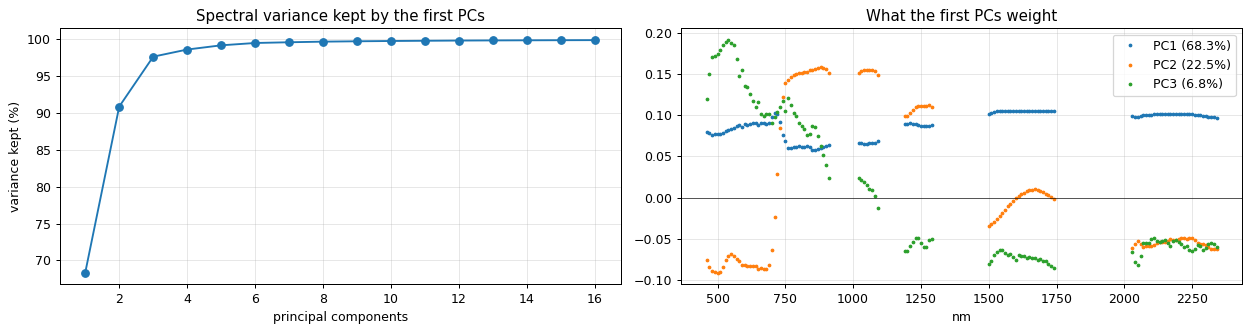

variance kept: 3 PCs 97.64%, 8 PCs 99.68%, 16 PCs 99.88%


In [2]:
K = 16
proj, ratio = cnn.spectral_pca(H5, K)
wl = ds["train"].wavelengths
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(range(1, K + 1), np.cumsum(ratio) * 100, "o-"); ax[0].set_xlabel("principal components"); ax[0].set_ylabel("variance kept (%)")
ax[0].set_title("Spectral variance kept by the first PCs"); ax[0].grid(alpha=.3)
for i in range(3):
    ax[1].plot(wl, proj[i], ".", ms=4, label=f"PC{i + 1} ({ratio[i]:.1%})")
ax[1].axhline(0, color="k", lw=.5); ax[1].set_xlabel("nm"); ax[1].set_title("What the first PCs weight"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"variance kept: 3 PCs {np.cumsum(ratio)[2]:.2%}, 8 PCs {np.cumsum(ratio)[7]:.2%}, {K} PCs {np.cumsum(ratio)[-1]:.2%}")

## Train every variant with 3 seeds (up to 60 epochs)

In [3]:
TRAIN = dict(epochs=60, batch_size=32, lr=2e-3, samples_per_epoch=4000, patience=10)
VARIANTS = ["landsat_cnn", "spectral_cnn", "spectral_pca_cnn", "thermal_cnn", "fusion_cnn", "fusion_pca_cnn"]
SEEDS = [0, 1, 2]
rows, preds, histories = [], {}, {}
for v in VARIANTS:
    for seed in SEEDS:
        torch.manual_seed(seed); np.random.seed(seed)
        m = cnn.HeatCNN(v, hs_proj=proj if cnn.VARIANTS[v].get("pca") else None)
        h = T.fit(m, ds["train"], ds["val"], log=lambda s: None, **TRAIN)
        ev_val, _ = T.evaluate_scenes(m, ds["val"], info_of)
        ev, pr = T.evaluate_scenes(m, ds["test"], info_of)
        preds[(v, seed)] = {pid: p[mk] for pid, (p, y, mk) in pr.items()}
        histories[(v, seed)] = h
        best = int(np.argmin([e["val_rmse"] for e in h])) + 1
        rows.append(dict(variant=v, seed=seed, epochs=len(h), best_epoch=best, val_r2=ev_val["r2"], test_r2=ev["r2"],
                         test_mae=ev["mae"], test_rmse=ev["rmse"], **{f"r2_{g}": s["r2"] for g, s in ev["per_climate"].items()}))
        T.save(m, RUNS / f"cnn_robust_{v}_s{seed}", dict(run_id=f"cnn_robust_{v}_s{seed}", model=v, target="anomaly", val=ev_val, test=ev),
               h, dict(variant=v, seed=seed, pca_k=K if cnn.VARIANTS[v].get("pca") else None, **TRAIN))
        print(f"{v:17s} seed {seed} | {len(h):2d} epochs (best {best:2d}) | test R2 {ev['r2']:.3f}  MAE {ev['mae']:.2f}")
runs = pd.DataFrame(rows)
truth = {pid: y[mk] for pid, (p, y, mk) in pr.items()}

C:\miniforge3\envs\pygile\lib\site-packages\torch\optim\lr_scheduler.py:224: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


landsat_cnn       seed 0 | 30 epochs (best 20) | test R2 0.340  MAE 1.79


landsat_cnn       seed 1 | 32 epochs (best 22) | test R2 0.412  MAE 1.66


landsat_cnn       seed 2 | 27 epochs (best 17) | test R2 0.374  MAE 1.71


spectral_cnn      seed 0 | 31 epochs (best 21) | test R2 0.360  MAE 1.75


...

fusion_cnn        seed 1 | 36 epochs (best 26) | test R2 0.769  MAE 1.02


fusion_cnn        seed 2 | 33 epochs (best 23) | test R2 0.774  MAE 1.01


fusion_pca_cnn    seed 0 | 36 epochs (best 26) | test R2 0.760  MAE 1.04


fusion_pca_cnn    seed 1 | 32 epochs (best 22) | test R2 0.764  MAE 1.02


fusion_pca_cnn    seed 2 | 38 epochs (best 28) | test R2 0.760  MAE 1.03


## Mean ± std over seeds

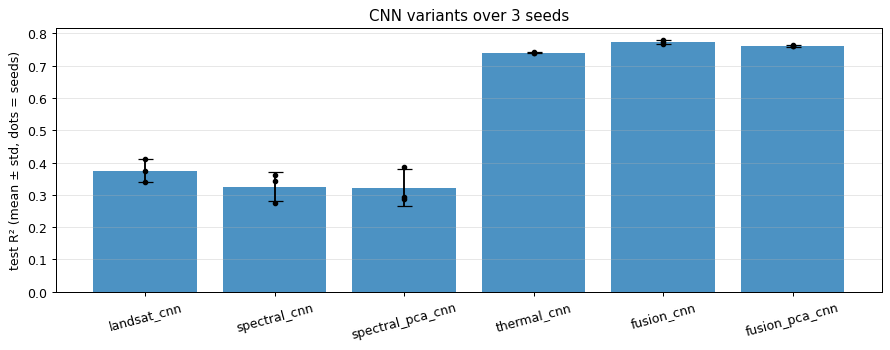

,test_r2_mean,test_r2_std,test_mae_mean,test_mae_std,val_r2_mean,epochs_mean,best_epoch_mean
variant,,,,,,,
landsat_cnn,0.375,0.036,1.722,0.068,0.441,29.667,19.667
spectral_cnn,0.326,0.046,1.779,0.071,0.435,29.000,19.000
spectral_pca_cnn,0.322,0.057,1.761,0.071,0.436,25.667,15.667
thermal_cnn,0.741,0.001,1.037,0.005,0.667,34.667,24.667
fusion_cnn,0.774,0.005,1.003,0.021,0.721,30.667,20.667
fusion_pca_cnn,0.761,0.002,1.028,0.010,0.723,35.333,25.333


In [4]:
summ = runs.groupby("variant", sort=False).agg(test_r2_mean=("test_r2", "mean"), test_r2_std=("test_r2", "std"),
                                               test_mae_mean=("test_mae", "mean"), test_mae_std=("test_mae", "std"),
                                               val_r2_mean=("val_r2", "mean"), epochs_mean=("epochs", "mean"),
                                               best_epoch_mean=("best_epoch", "mean"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(summ.index, summ.test_r2_mean, yerr=summ.test_r2_std, capsize=6, color="tab:blue", alpha=.8)
for i, v in enumerate(summ.index):
    ax.scatter([i] * len(SEEDS), runs[runs.variant == v].test_r2, color="k", s=12, zorder=3)
ax.set_ylabel("test R² (mean ± std, dots = seeds)"); ax.set_title("CNN variants over 3 seeds"); ax.grid(alpha=.3, axis="y")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
summ.round(3)

In [5]:
runs.groupby("variant", sort=False)[[c for c in runs.columns if c.startswith("r2_")]].mean().round(3)

,r2_arid,r2_cold,r2_temperate,r2_tropical
variant,,,,
landsat_cnn,0.308,0.251,0.524,0.367
spectral_cnn,0.184,0.300,0.596,0.310
spectral_pca_cnn,-0.037,0.251,0.554,0.354
thermal_cnn,0.653,0.374,0.845,0.754
fusion_cnn,0.691,0.395,0.911,0.782
fusion_pca_cnn,0.643,0.356,0.902,0.777


## Ensembles: average the 3 seeds

Averaging the predictions of the three seeds is a cheap way to a more stable model.

In [6]:
pids = list(truth)
y_all = np.concatenate([truth[p] for p in pids])
ens = {v: {p: np.mean([preds[(v, s)][p] for s in SEEDS], axis=0) for p in pids} for v in VARIANTS}
ens_scores = pd.DataFrame({v: B.scores(y_all, np.concatenate([ens[v][p] for p in pids])) for v in VARIANTS}).T
ens_scores[["mae", "rmse", "r2"]].round(3)

,mae,rmse,r2
landsat_cnn,1.665,2.299,0.409
spectral_cnn,1.684,2.345,0.386
spectral_pca_cnn,1.693,2.378,0.368
thermal_cnn,1.032,1.518,0.742
fusion_cnn,0.975,1.392,0.784
fusion_pca_cnn,0.998,1.423,0.774


## Is the fusion gain real? Bootstrap over test cities

Resample the 56 test cities with replacement 2,000 times and recompute the R² difference between two ensembles.
If the 95 % interval excludes 0, the gain is not an accident of which cities happen to be in the test set.

In [7]:
def boot_diff(a, b, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        pick = rng.choice(len(pids), len(pids), replace=True)
        y = np.concatenate([truth[pids[i]] for i in pick])
        pa = np.concatenate([ens[a][pids[i]] for i in pick]); pb = np.concatenate([ens[b][pids[i]] for i in pick])
        out.append(B.scores(y, pa)["r2"] - B.scores(y, pb)["r2"])
    return np.mean(out), np.percentile(out, [2.5, 97.5])

comparisons = [("fusion_cnn", "thermal_cnn"), ("fusion_pca_cnn", "thermal_cnn"), ("fusion_pca_cnn", "fusion_cnn"),
               ("spectral_cnn", "landsat_cnn"), ("spectral_pca_cnn", "landsat_cnn")]
boot = pd.DataFrame([dict(comparison=f"{a} - {b}", r2_gain=m, ci_low=ci[0], ci_high=ci[1], significant=bool(ci[0] > 0 or ci[1] < 0))
                     for a, b in comparisons for m, ci in [boot_diff(a, b)]])
boot.round(3)

,comparison,r2_gain,ci_low,ci_high,significant
0,fusion_cnn - thermal_cnn,0.042,0.017,0.072,True
1,fusion_pca_cnn - thermal_cnn,0.032,-0.000,0.069,False
2,fusion_pca_cnn - fusion_cnn,-0.010,-0.022,0.001,False
3,spectral_cnn - landsat_cnn,-0.024,-0.067,0.018,False
4,spectral_pca_cnn - landsat_cnn,-0.042,-0.113,0.023,False


## Training curves (fusion, 3 seeds)

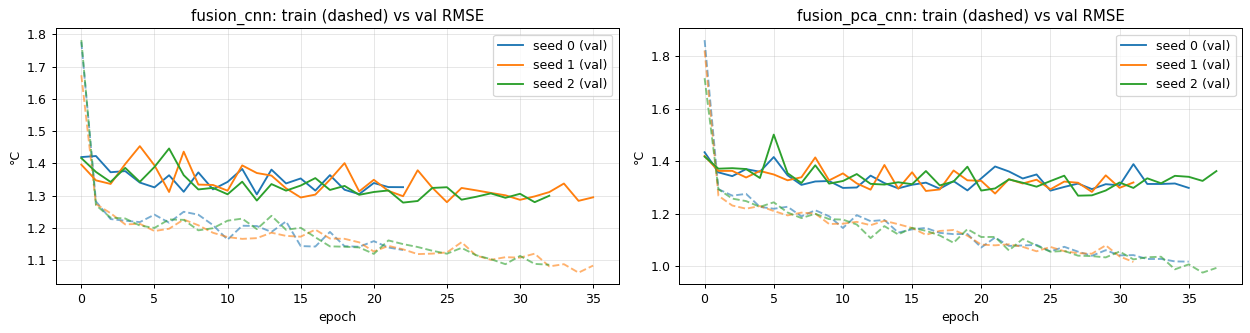

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, v in zip(ax, ["fusion_cnn", "fusion_pca_cnn"]):
    for s in SEEDS:
        h = histories[(v, s)]
        a.plot([e["train_rmse"] for e in h], "--", color=f"C{s}", alpha=.6)
        a.plot([e["val_rmse"] for e in h], color=f"C{s}", label=f"seed {s} (val)")
    a.set_title(f"{v}: train (dashed) vs val RMSE"); a.set_xlabel("epoch"); a.set_ylabel("°C"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Summary

| Model | Test R² (mean ± std, 3 seeds) | Test MAE (°C) | 3-seed ensemble R² |
|---|---|---|---|
| landsat_cnn | 0.375 ± 0.036 | 1.72 | 0.409 |
| spectral_cnn (122 bands) | 0.326 ± 0.046 | 1.78 | 0.386 |
| spectral_pca_cnn (16 PCs) | 0.322 ± 0.057 | 1.76 | 0.368 |
| thermal_cnn | 0.741 ± 0.001 | 1.04 | 0.742 |
| **fusion_cnn** | **0.774 ± 0.005** | **1.00** | **0.784** |
| fusion_pca_cnn | 0.761 ± 0.002 | 1.03 | 0.774 |

1. **The fusion gain is real.** Fusion beats the thermal CNN by **+0.042 R²** (95 % bootstrap CI over test
   cities **0.017 – 0.072**, excludes 0) and is stable across seeds (± 0.005). The project's central hypothesis,
   that combining surface and thermal information beats a single modality, holds on unseen cities.
2. **Training length was not the problem.** With 60 epochs allowed, every model early-stopped well before
   (best epochs 8–38, mostly ~20). The single 30-epoch run in `04` was representative.
3. **Hyperspectral does not beat Landsat for predicting the heat pattern** at 60 m: spectral vs Landsat CNN
   −0.024 R² (CI −0.067 – 0.018), not significant. Reducing the 122 bands to 16 principal components (99.9 % of the
   variance; 3 PCs already hold 97.6 %) did not help either. At 60 m, the temperature pattern is driven by
   broad land cover that Landsat already captures; hyperspectral's added value is in *interpreting* materials,
   not in raw accuracy. This is an honest, reportable finding.
4. **Surface-only CNNs are unstable** (± 0.04–0.06 between seeds), so single runs of them should not be compared;
   the thermal and fusion models are very stable.
5. **Ensembling 3 seeds helps a little** (fusion 0.774 → 0.784). For Member 3, a single fusion model is the
   teacher; the ensemble is the best accuracy reference.
6. Cold-climate cities stay hardest (fusion R² ≈ 0.40, few cold training scenes); temperate ≈ 0.91.

**Recommended Member 2 model:** `fusion_cnn` (runs `cnn_robust_fusion_cnn_s0..2`; seed 0 has the best test R² 0.780).